## Hydrodynamic model of the Southern North Sea

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from helper import get_altimetry_obs, get_u_v_point_obs, get_wl_point_obs
from helper import plot_shred_reconstruction

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSHRED import mSHRED

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


## Load Data and Measurements

In [3]:
# folders
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/Mesh_8000_elems_HD_v2.mesh"
obs_fldr  = "datasets/observations/"

msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)

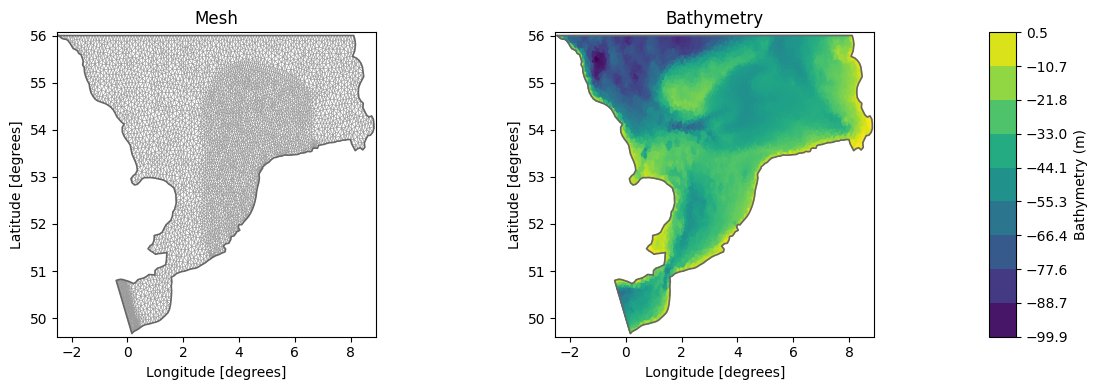

In [4]:
# plot geometry
geom = dfs.geometry

fig, axs = plt.subplots(1,2, figsize = (12,4))
geom.plot.mesh(ax=axs[0])
geom.plot(ax=axs[1])
plt.tight_layout()
plt.show()

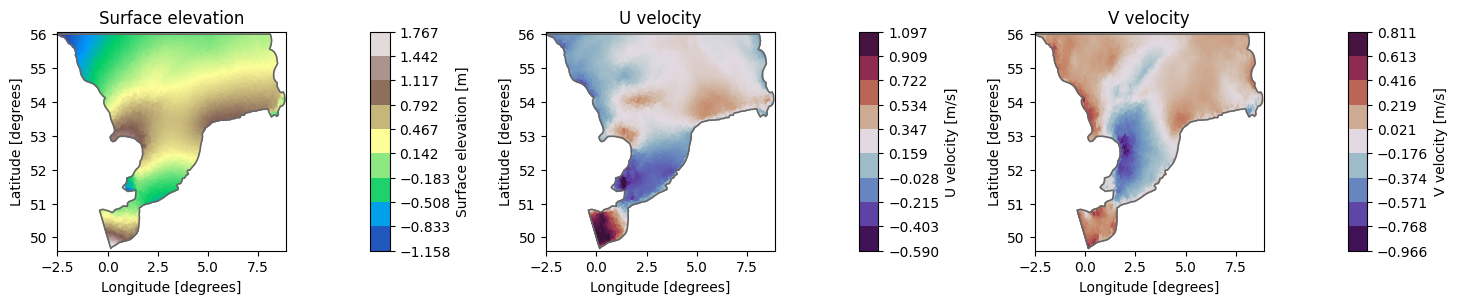

In [5]:
# plot a simulation
ds = dfs.read()

dsH = ds["Surface elevation"]
dsU = ds["U velocity"]
dsV = ds["V velocity"]

plot_time = ds.time[-1]
fig,axs = plt.subplots(1, 3, figsize=(15,5))
dsH.sel(time=plot_time).plot(ax=axs[0], title="Surface elevation", cmap = "terrain")
dsU.sel(time=plot_time).plot(ax=axs[1], title="U velocity", cmap = "twilight_shifted")
dsV.sel(time=plot_time).plot(ax=axs[2], title="V velocity", cmap = "twilight_shifted")
plt.tight_layout()
plt.show()


<Axes: >

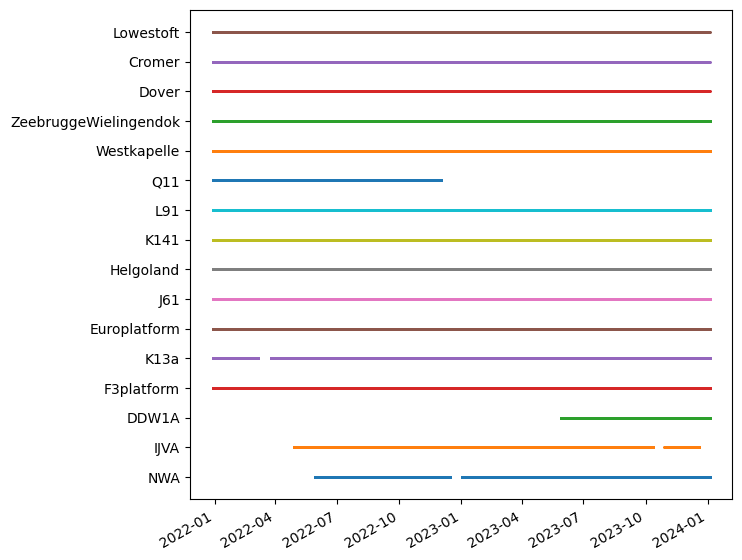

In [6]:
# sensor coverage

wl_stations = get_wl_point_obs()
ms.plotting.temporal_coverage(wl_stations)

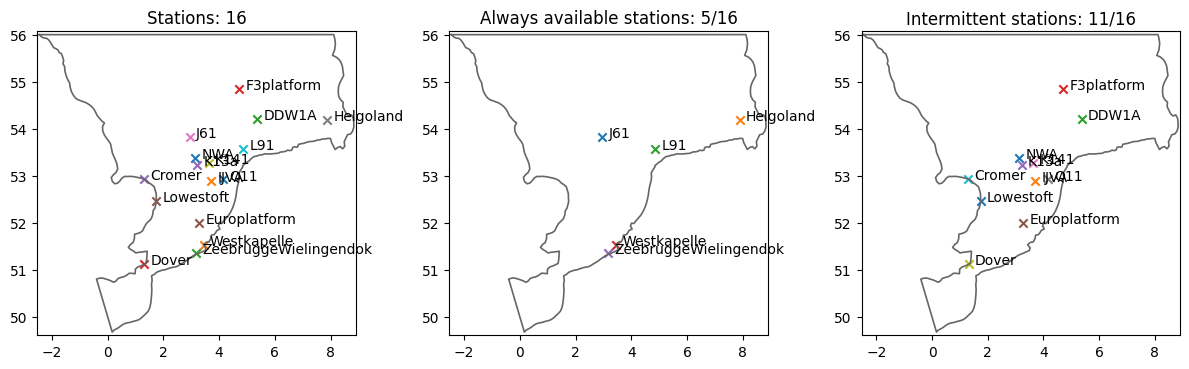

In [7]:
# Select stations with full temporal coverage

stations = []
available_stations = []
intermittent_stations = []
for i in range(len(wl_stations)):
    stations.append(wl_stations[i])
    if ds.time.isin(wl_stations[i].time).all():
        available_stations.append(wl_stations[i])
    else:
        intermittent_stations.append(wl_stations[i])

fig, axs = plt.subplots(1,3, figsize = (12,4))
ms.plotting.spatial_overview(stations, mod = msh.geometry, figsize = (5,5), ax=axs[0], title=f"Stations: {len(stations)}")
ms.plotting.spatial_overview(available_stations, mod = msh.geometry, figsize = (5,5), ax=axs[1], title=f"Always available stations: {len(available_stations)}/{len(stations)}")
ms.plotting.spatial_overview(intermittent_stations, mod = msh.geometry, figsize = (5,5), ax=axs[2], title=f"Intermittent stations: {len(intermittent_stations)}/{len(stations)}")

plt.tight_layout()
plt.show()


In [8]:
# Extract water level measurements

measurements = np.full((ds.time.shape[0], len(stations)), np.nan)

for i in range(len(stations)):
    
    stn_data = pd.read_csv(obs_fldr + stations[i].name + "_wl.csv", index_col = 0)
    measurements[:,i] = stn_data["water_level_filtered"].reindex(ds.time.strftime("%Y-%m-%d %H:%M:%S")).values 

# free memory
del stn_data

In [9]:
# Extract the values and convert to torch tensors

# remove nans from H, U, V 
dsH = dsH.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsU = dsU.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]
dsV = dsV.values[:,~np.isnan(ds["Surface elevation"].values).any(axis=0)]

# outputs
H = torch.tensor(dsH, dtype=torch.float32)
U = torch.tensor(dsU, dtype=torch.float32)
V = torch.tensor(dsV, dtype=torch.float32)

# inputs
measurements = torch.tensor(measurements, dtype=torch.float32)

# print the shape of the arrays
print("H shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)
print("Measurements shape:", measurements.shape)

# free memory
del dsH, dsU, dsV

H shape: torch.Size([35039, 8532])
U shape: torch.Size([35039, 8532])
V shape: torch.Size([35039, 8532])
Measurements shape: torch.Size([35039, 16])


In [10]:
ERRORS = []

In [11]:

# Data manager

lags = 24
manager = DataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(H, id = "Surface elevation" , compress = 12, measurements = measurements)
manager.add_data(U, id = "U velocity", compress = 40)
manager.add_data(V, id = "V velocity", compress = 68)

# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True, masking_type="mask_data")

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Nuber of nan values in measurements after imputation: 117189 

Residual energy of Surface elevation after keeping 12 modes: 0.1678 %
Residual energy of U velocity after keeping 40 modes: 0.1947 %
Residual energy of V velocity after keeping 68 modes: 0.1872 %

Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 117189

Data shapes after preparation:
Train:	 torch.Size([28031, 24, 16]) -> torch.Size([28031, 120])
Val:	 torch.Size([3504, 24, 16]) -> torch.Size([3504, 120])
Test:	 torch.Size([3504, 24, 16]) -> torch.Size([3504, 120])

Input shape for the model: 16
Output shape for the model: 120


## Idea 3.0: TSHRED

Starting training...


Training: 100%|██████████| 200/200 [30:41<00:00,  9.21s/it, Train Loss=0.0032, Val Loss=0.0041, Patience=9, Best Val Loss=0.0041, LR=0.00e+00] 

Training completed with best validation loss: 0.0041


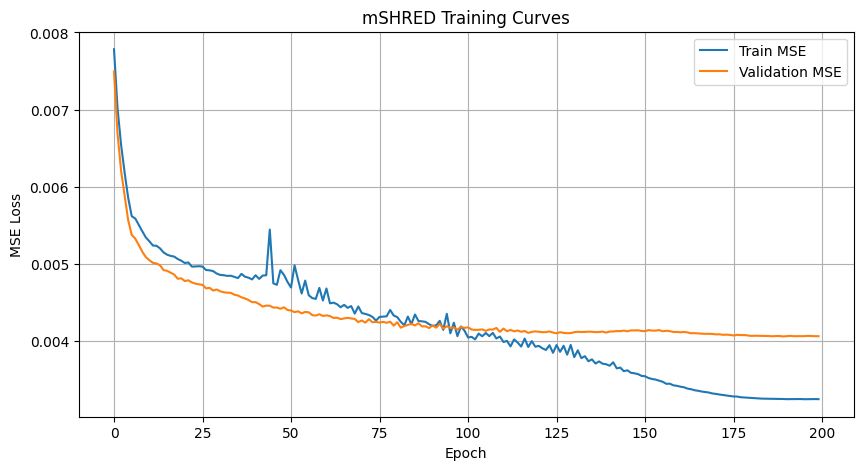

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(3.0) TSHRED,0.003245,0.004063,0.009955,0.115501,0.124957,0.197233


In [12]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type= "mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset,masking_type= "mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset,masking_type= "mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset,masking_type= "mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.0) TSHRED",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_0_tshred.png


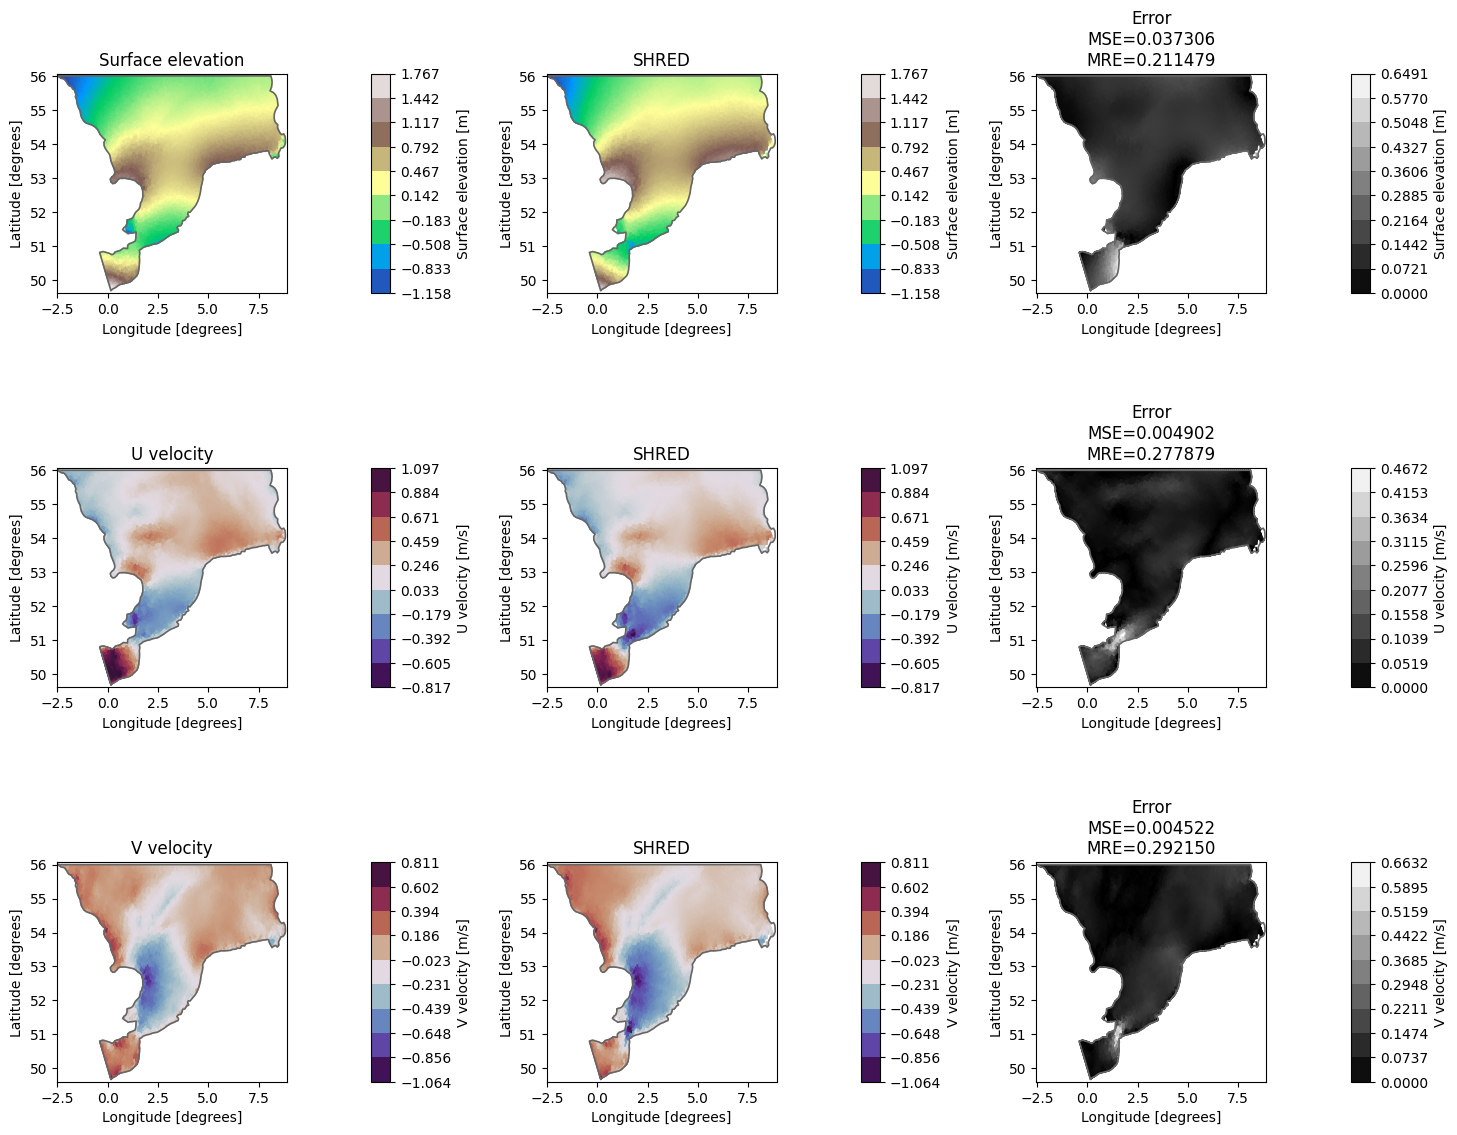

In [13]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_0_tshred")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.A: Mask double channels

Starting training...


Training:  92%|█████████▏| 184/200 [27:18<02:22,  8.91s/it, Train Loss=0.0033, Val Loss=0.0041, Patience=59, Best Val Loss=0.0041, LR=1.38e-05]

Early stopping at epoch 185
Training completed with best validation loss: 0.0041


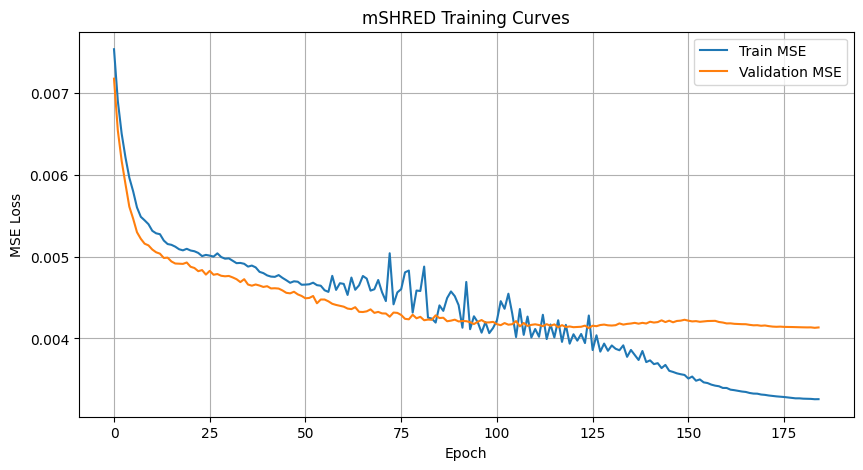

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(3.0) TSHRED,0.003245,0.004063,0.009955,0.115501,0.124957,0.197233
1,(mSHRED): TR + MLP,(3.A) Mask double channels,0.003257,0.004131,0.010034,0.115559,0.126156,0.197226


In [14]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=True,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type= "mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset,masking_type= "mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset,masking_type= "mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset,masking_type= "mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.A) Mask double channels",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_A_mask_double_channels.png


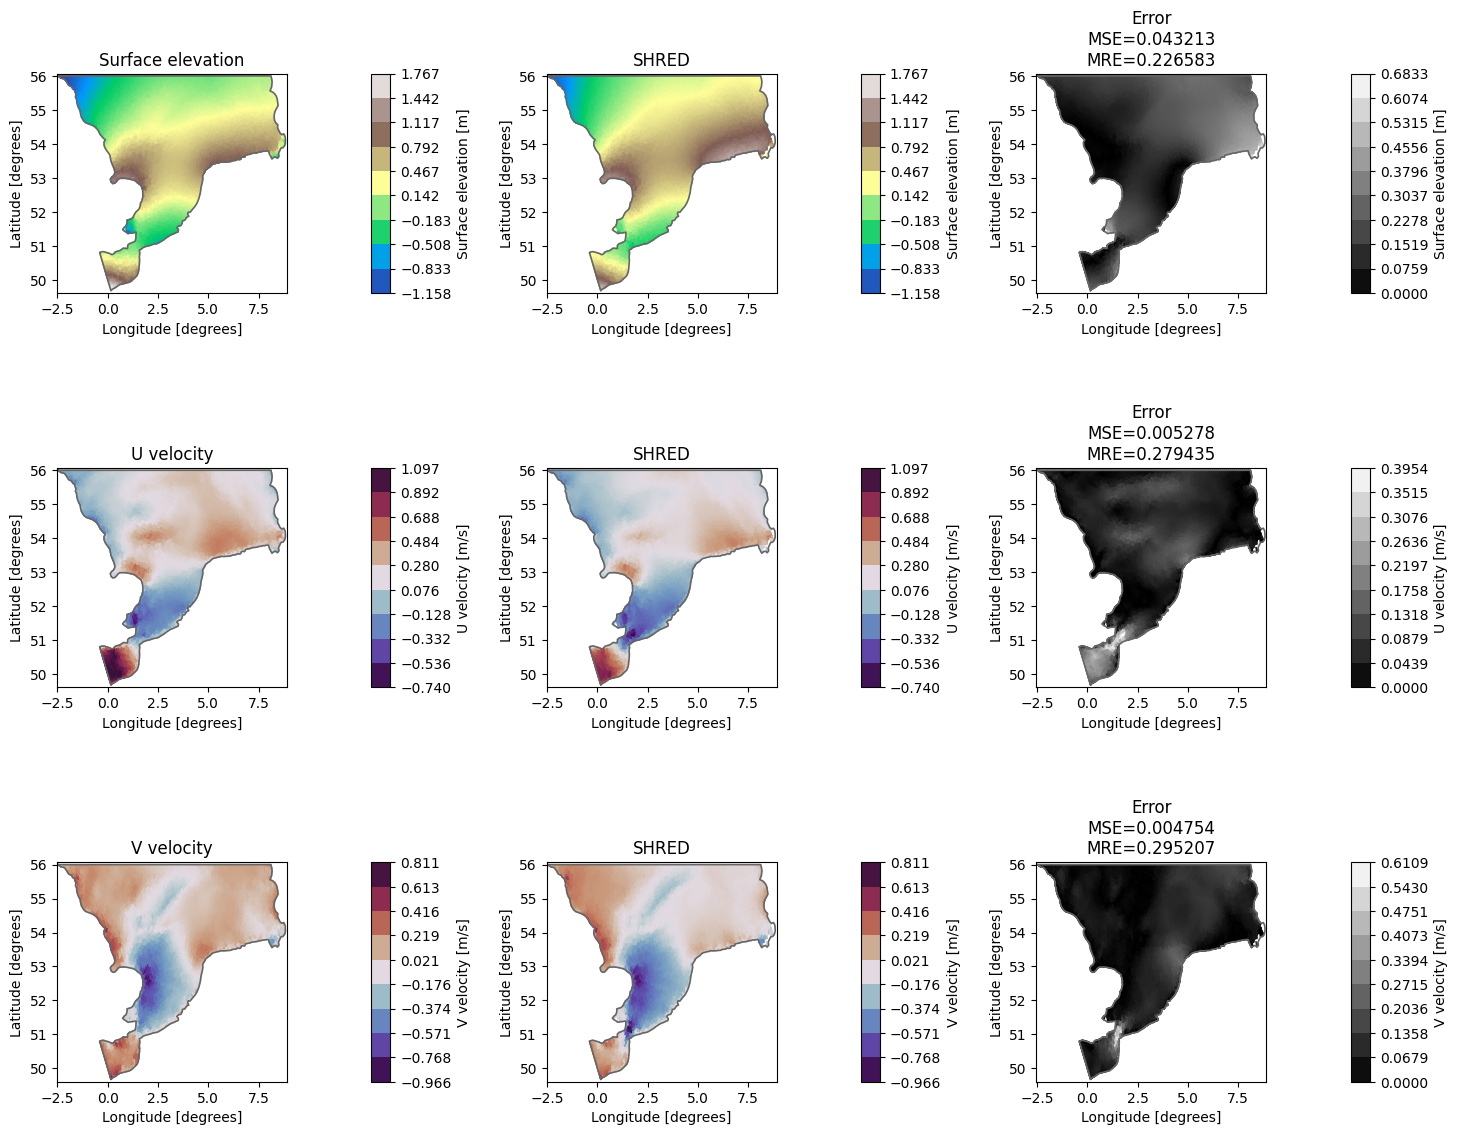

In [15]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_A_mask_double_channels")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.B: Mask in the hidden space

Starting training...


Training: 100%|██████████| 200/200 [29:57<00:00,  8.99s/it, Train Loss=0.0032, Val Loss=0.0041, Patience=0, Best Val Loss=0.0041, LR=0.00e+00] 

Training completed with best validation loss: 0.0041


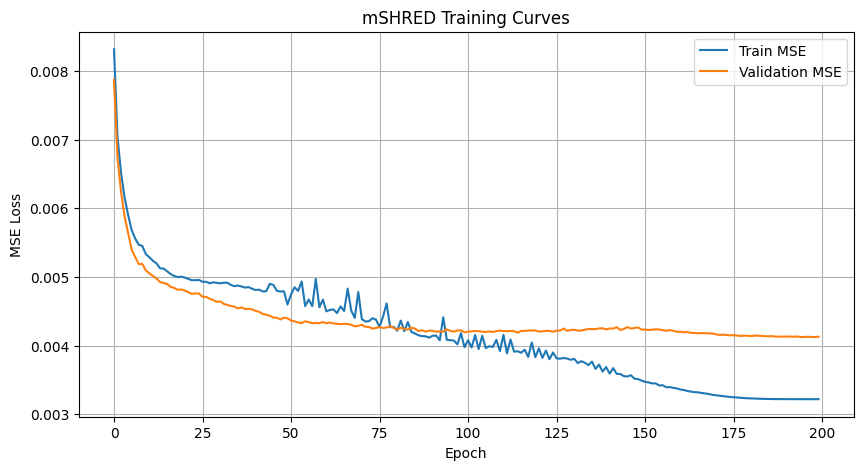

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(3.0) TSHRED,0.003245,0.004063,0.009955,0.115501,0.124957,0.197233
1,(mSHRED): TR + MLP,(3.A) Mask double channels,0.003257,0.004131,0.010034,0.115559,0.126156,0.197226
2,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.003220,0.004128,0.010143,0.115141,0.126194,0.199242


In [16]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_hidden_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.B) Mask the hidden state",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_B_mask_hidden_state.png


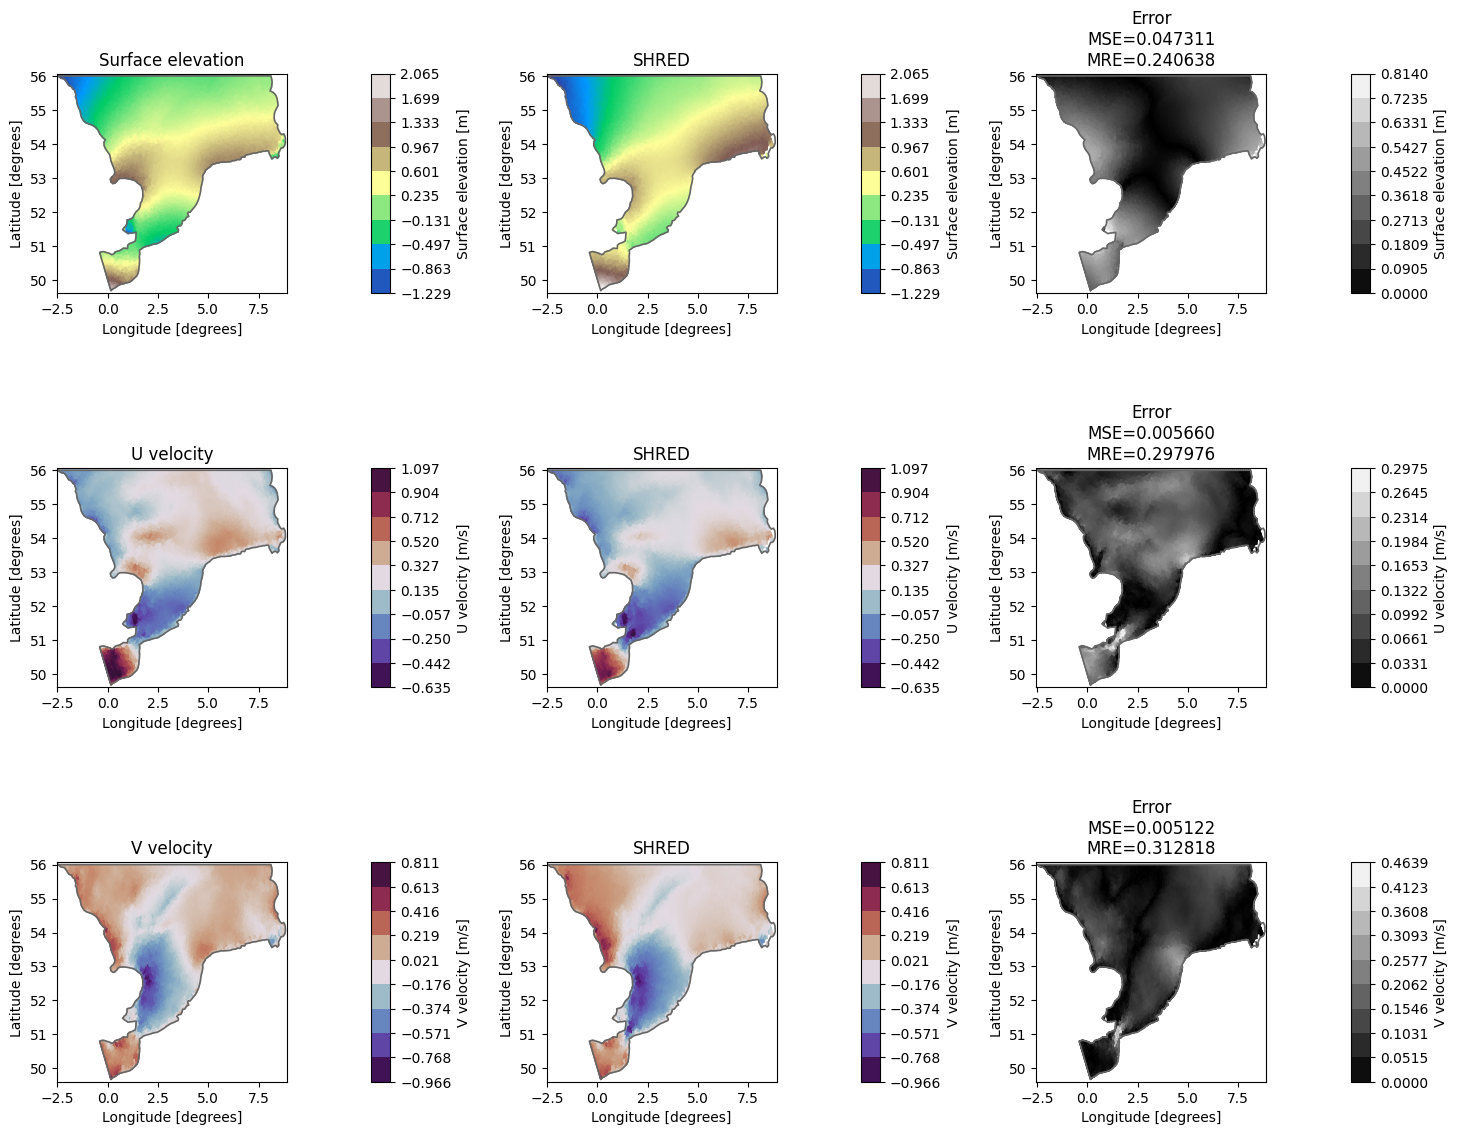

In [17]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_B_mask_hidden_state")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.C: Mask in the attention block

Starting training...


Training: 100%|██████████| 200/200 [32:31<00:00,  9.76s/it, Train Loss=0.0032, Val Loss=0.0040, Patience=5, Best Val Loss=0.0040, LR=0.00e+00] 

Training completed with best validation loss: 0.0040


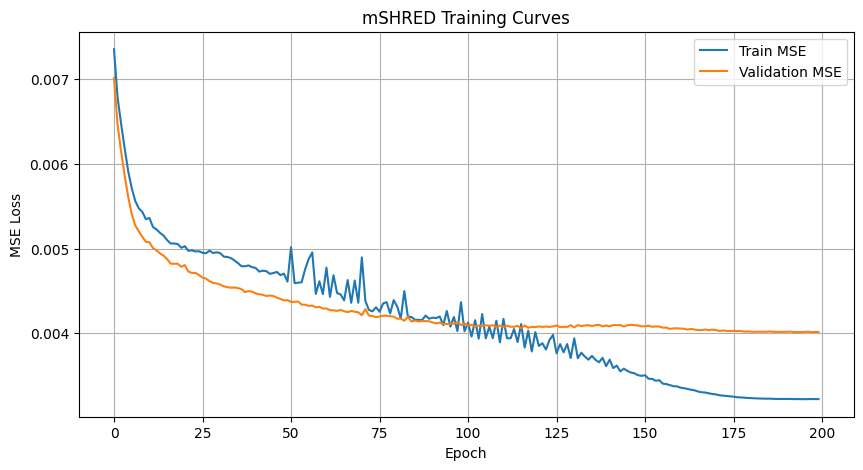

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(3.0) TSHRED,0.003245,0.004063,0.009955,0.115501,0.124957,0.197233
1,(mSHRED): TR + MLP,(3.A) Mask double channels,0.003257,0.004131,0.010034,0.115559,0.126156,0.197226
2,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.003220,0.004128,0.010143,0.115141,0.126194,0.199242
3,(mSHRED): TR + MLP,(3.C) Mask in the attention block,0.003222,0.004016,0.009793,0.115185,0.124492,0.195526


In [18]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=False,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.C) Mask in the attention block",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_C_mask_attention_block.png


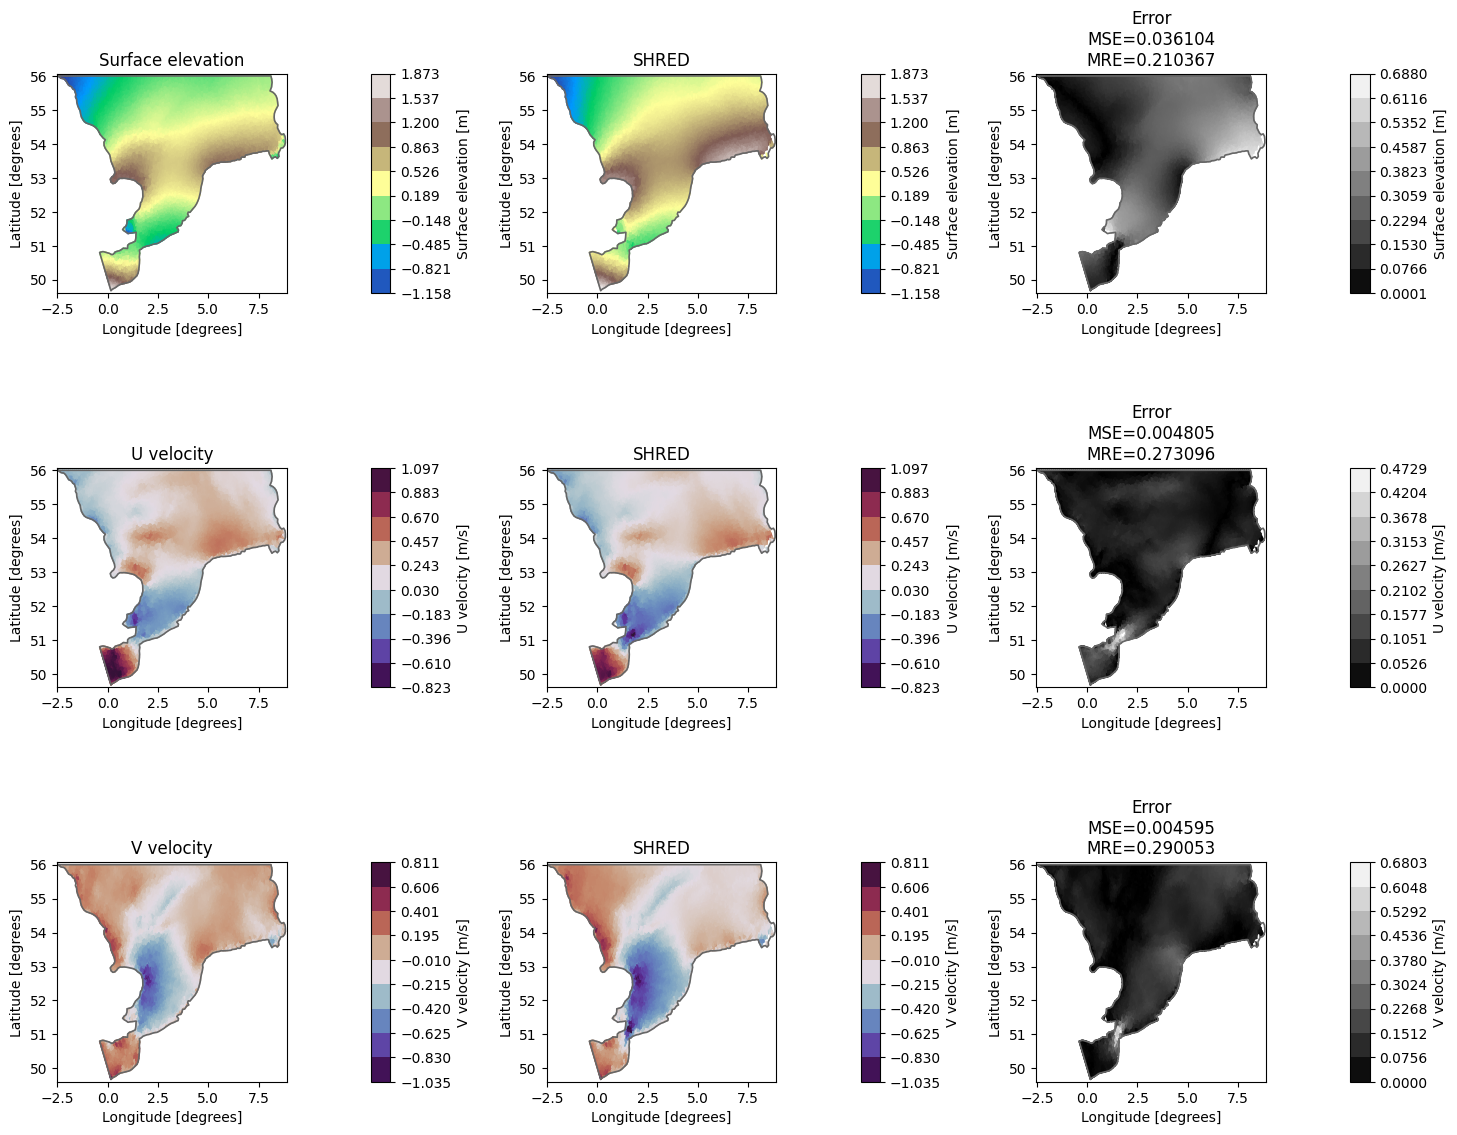

In [19]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_C_mask_attention_block")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.D: Attention mask + double channels

Starting training...


Training: 100%|██████████| 200/200 [34:16<00:00, 10.28s/it, Train Loss=0.0033, Val Loss=0.0041, Patience=10, Best Val Loss=0.0041, LR=0.00e+00]

Training completed with best validation loss: 0.0041


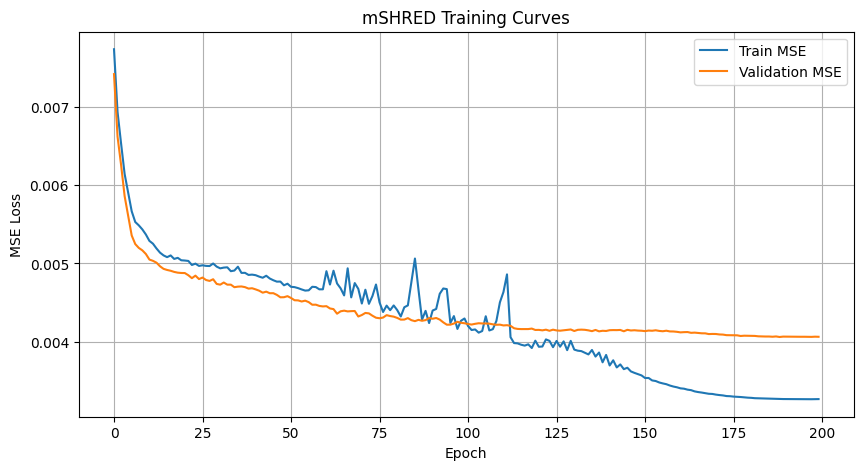

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(3.0) TSHRED,0.003245,0.004063,0.009955,0.115501,0.124957,0.197233
1,(mSHRED): TR + MLP,(3.A) Mask double channels,0.003257,0.004131,0.010034,0.115559,0.126156,0.197226
2,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.003220,0.004128,0.010143,0.115141,0.126194,0.199242
3,(mSHRED): TR + MLP,(3.C) Mask in the attention block,0.003222,0.004016,0.009793,0.115185,0.124492,0.195526
4,(mSHRED): TR + MLP,(3.D) Double masking,0.003267,0.004061,0.009820,0.115710,0.125179,0.195843


In [20]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=True,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.D) Double masking",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_D_double_masking.png


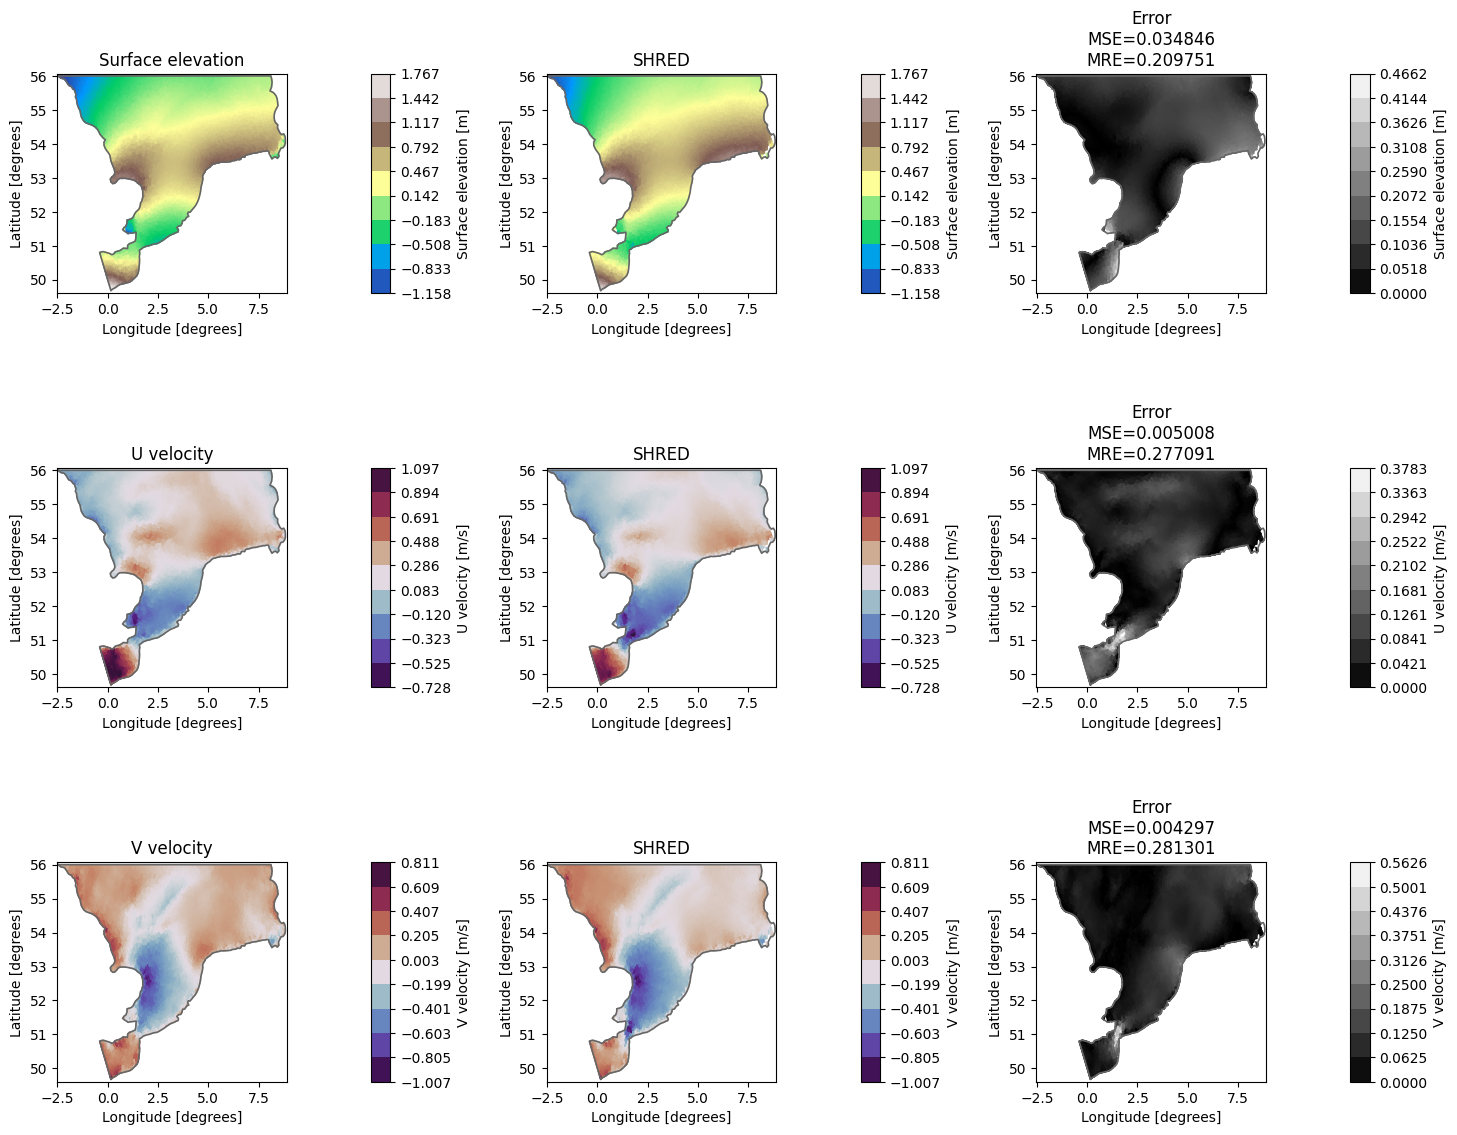

In [21]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_D_double_masking")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.E: learn the mask in the softmax


Starting training...


Training: 100%|██████████| 200/200 [41:00<00:00, 12.30s/it, Train Loss=0.0031, Val Loss=0.0041, Patience=0, Best Val Loss=0.0041, LR=0.00e+00] 

Training completed with best validation loss: 0.0041


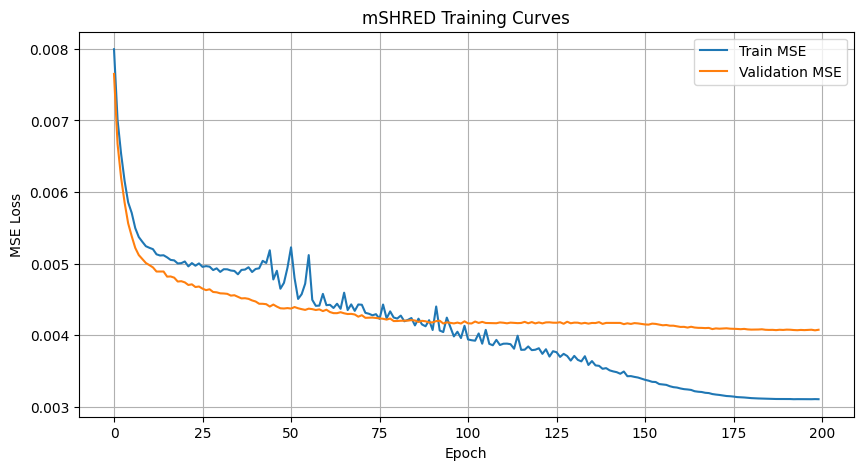

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(3.0) TSHRED,0.003245,0.004063,0.009955,0.115501,0.124957,0.197233
1,(mSHRED): TR + MLP,(3.A) Mask double channels,0.003257,0.004131,0.010034,0.115559,0.126156,0.197226
2,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.003220,0.004128,0.010143,0.115141,0.126194,0.199242
3,(mSHRED): TR + MLP,(3.C) Mask in the attention block,0.003222,0.004016,0.009793,0.115185,0.124492,0.195526
4,(mSHRED): TR + MLP,(3.D) Double masking,0.003267,0.004061,0.009820,0.115710,0.125179,0.195843
5,(mSHRED): TR + MLP,(3.E) Transformer Learned mask,0.003109,0.004077,0.009994,0.113584,0.125009,0.197488


In [22]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.E) Transformer Learned mask",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_D_learn_mask_softmax.png


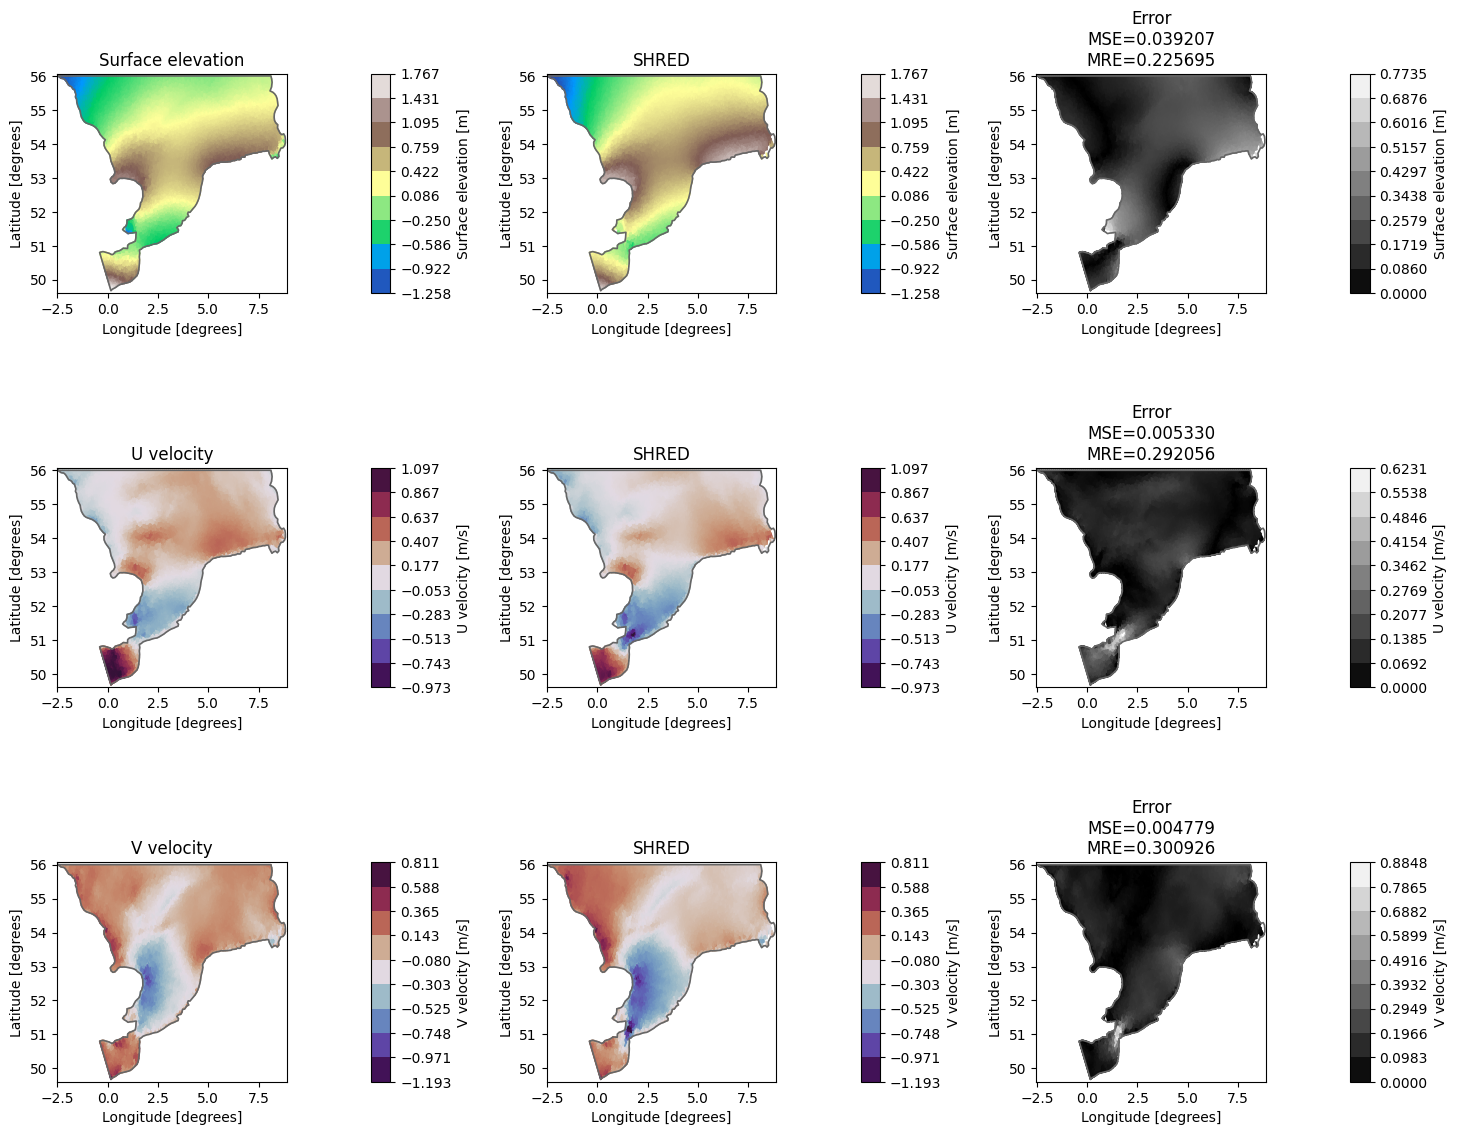

In [23]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_D_learn_mask_softmax")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Idea 3.F: Learned mask + double channels


Starting training...


Training: 100%|██████████| 200/200 [40:45<00:00, 12.23s/it, Train Loss=0.0032, Val Loss=0.0041, Patience=0, Best Val Loss=0.0041, LR=0.00e+00] 

Training completed with best validation loss: 0.0041


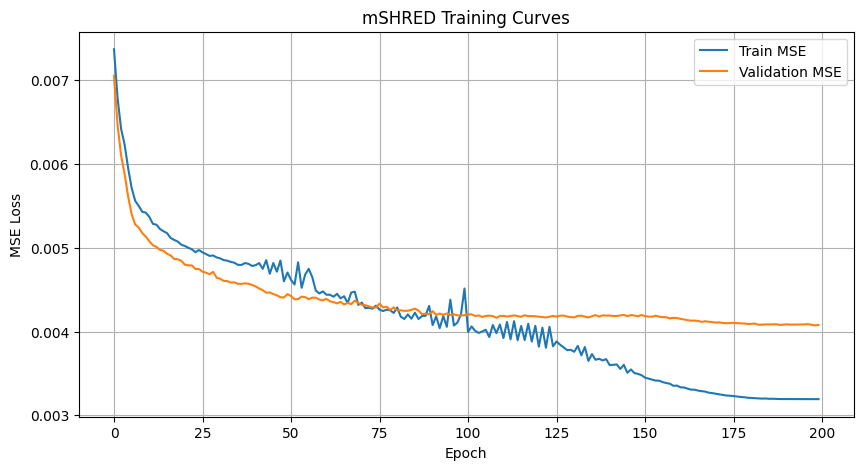

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(3.0) TSHRED,0.003245,0.004063,0.009955,0.115501,0.124957,0.197233
1,(mSHRED): TR + MLP,(3.A) Mask double channels,0.003257,0.004131,0.010034,0.115559,0.126156,0.197226
2,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.003220,0.004128,0.010143,0.115141,0.126194,0.199242
3,(mSHRED): TR + MLP,(3.C) Mask in the attention block,0.003222,0.004016,0.009793,0.115185,0.124492,0.195526
4,(mSHRED): TR + MLP,(3.D) Double masking,0.003267,0.004061,0.009820,0.115710,0.125179,0.195843
5,(mSHRED): TR + MLP,(3.E) Transformer Learned mask,0.003109,0.004077,0.009994,0.113584,0.125009,0.197488
6,(mSHRED): TR + MLP,(3.F) Transformer Learned mask + double channels,0.003192,0.004080,0.009960,0.114949,0.125449,0.197499


In [24]:

# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask",
    encoder_depth=2,
    input_size=nn_input_shape,
    n_heads=4,
    dim_feedforward=64,
    hidden_size=64,
    input_length=lags,

    # Decoder
    decoder="mlp",
    decoder_hidden_sizes=[100],
    output_size=nn_output_shape,

    # Shared
    dropout=0.1,
    double_channels=True,
)

mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred,
    train_dataset,
    val_dataset,
    optimizer="AdamW",
    lr=1e-3,
    num_epochs=200,
    lr_scheduler="CosineAnnealingLR",
    scheduler_step_size=200,
    patience=60,
    verbose=True,
    masking_type="mask_data"
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('mSHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

# MSE and MRE
train_mse, train_mre = evaluate(mshred, train_dataset, masking_type="mask_data")
val_mse, val_mre = evaluate(mshred, val_dataset, masking_type="mask_data")
test_mse, test_mre = evaluate(mshred, test_dataset, masking_type="mask_data")
test_error = {
    "model": f"(mSHRED): TR + MLP",
    "type" : "(3.F) Transformer Learned mask + double channels",
    "train-mse": float(train_mse),
    "val-mse": float(val_mse),
    "test-mse": float(test_mse),
    "train-mre": float(train_mre),
    "val-mre": float(val_mre),
    "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/HYDRO/outputs/shred_3_F_learn_mask_double_channels.png


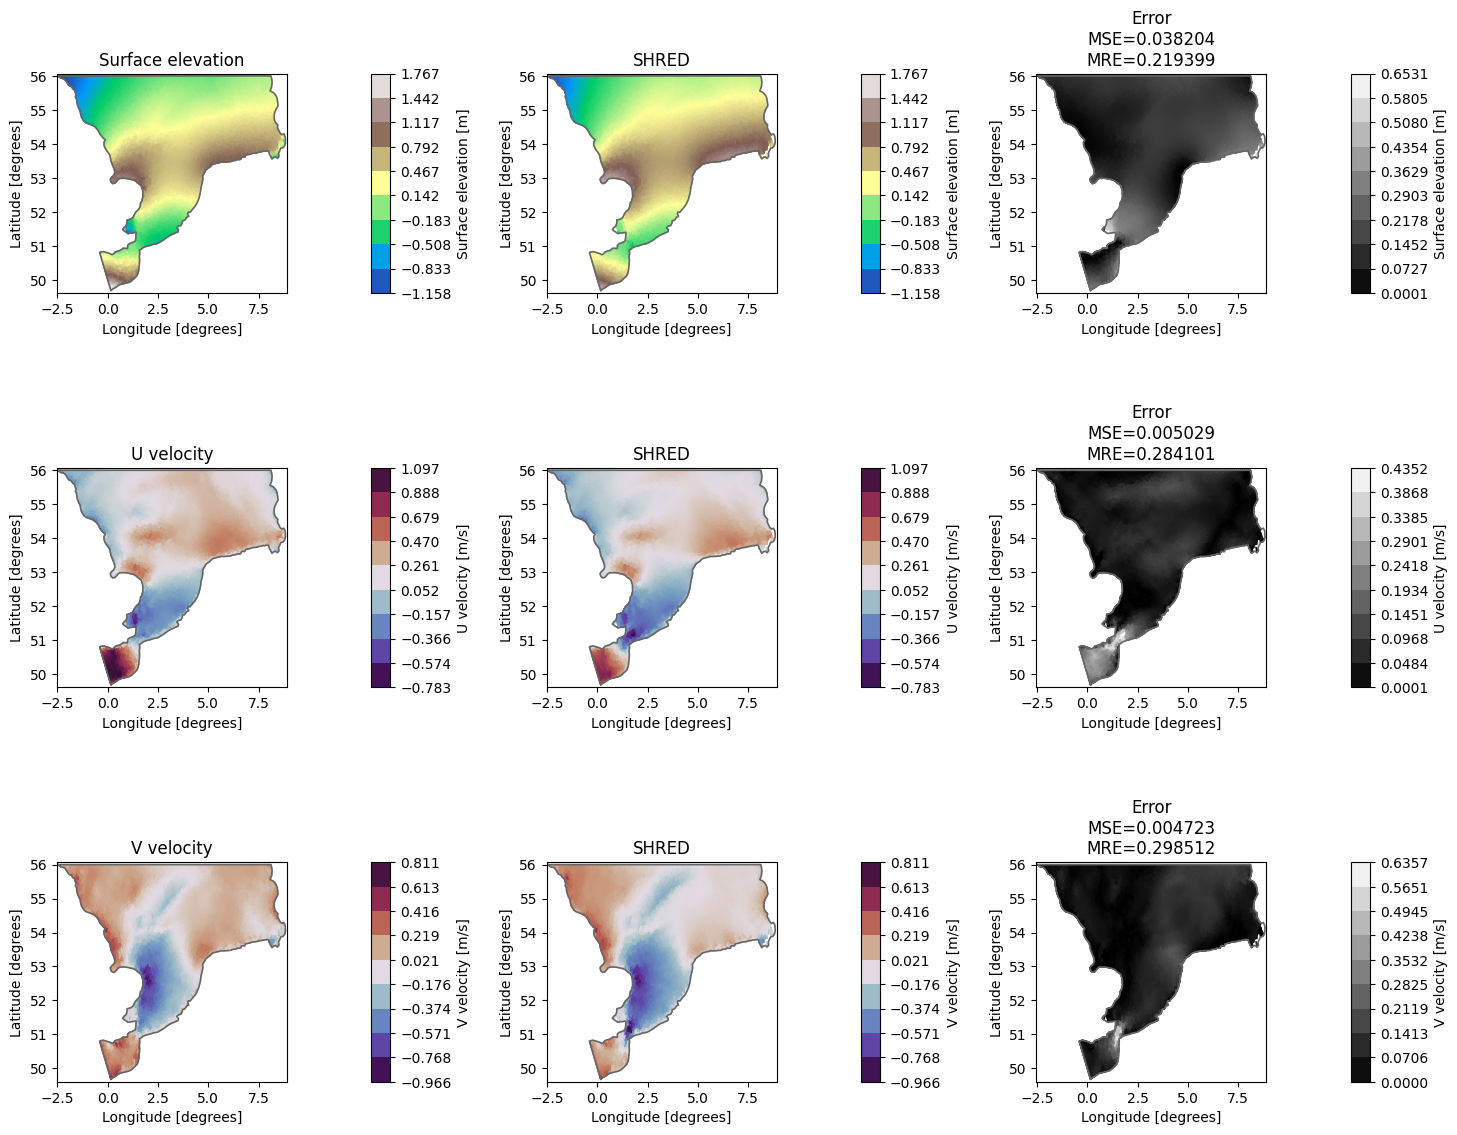

In [25]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="3_F_learn_mask_double_channels")

del engine, test_reconstruction, ds_shred, ds_error, mshred

## Masking Results

In [4]:
# load data from csv 
data = pd.read_csv("results_df/notebook2/dataframe_errors.csv")
display(data)

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(3.0) TSHRED,0.003155,0.004088,0.010537,0.115080,0.126510,0.203894
1,(mSHRED): TR + MLP,(3.A) Mask double channels,0.003128,0.004096,0.010356,0.114417,0.126669,0.202047
2,(mSHRED): TR + MLP,(3.B) Mask the hidden state,0.003558,0.004221,0.011088,0.122414,0.128739,0.209905
3,(mSHRED): TR + MLP,(3.C) Mask in the attention block,0.003075,0.004094,0.010736,0.113912,0.126809,0.205159
4,(mSHRED): TR + MLP,(3.D) Double masking,0.003079,0.004106,0.010648,0.113606,0.126626,0.204904
5,(mSHRED): TR + MLP,(3.E) Transformer Learned mask,0.003323,0.004237,0.010771,0.118283,0.128959,0.207328
6,(mSHRED): TR + MLP,(3.F) Transformer Learned mask + double channels,0.002991,0.004030,0.010580,0.112265,0.125829,0.205207
